# Pesquisa Informada — Greedy Best-First Search e A\*

**Inteligência Artificial 2026/27 — Grupo G05**

A pesquisa informada usa uma **heurística** (uma estimativa de quanto falta) para escolher que estado explorar a seguir. Neste notebook:

- **Greedy Best-First Search** — escolhe sempre o estado que *parece* mais perto do fim (só olha para a heurística). É rápido, mas não garante a melhor solução.
- **A\*** — escolhe o estado com menor custo já feito + estimativa do que falta. *(Secção por completar.)*

Como pede o enunciado, cada algoritmo usa **duas heurísticas**, mostram-se as **rotas dos 2 veículos do tiny** e conta-se o número de **nós expandidos**.

O código está em `src/informed.py`.

## 1. Preparação

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt

# Pasta principal do projeto (funciona a partir da raiz ou da pasta notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.model import Problem, check_solution, print_solution
from src.informed import (greedy_search, heuristica1, heuristica2,
                          sucessores, estado_viavel, terminou)

problemas = {nome: Problem.from_csv(RAIZ / nome) for nome in ["data_tiny", "data_small"]}
heuristicas = {"H1": heuristica1, "H2": heuristica2}
for nome, p in problemas.items():
    print(f"{nome}: {len(p.orders)} encomendas, {len(p.requests)} itens, {len(p.vehicles)} veículos")

data_tiny: 12 encomendas, 40 itens, 2 veículos
data_small: 25 encomendas, 80 itens, 2 veículos


## 2. O problema como pesquisa

| Elemento | No nosso problema |
|---|---|
| **Estado** | "fotografia" do momento: onde está cada veículo, a que horas fica livre, quanto leva, e em que fase está cada item (no produtor, no veículo, no armazém, carregado ou entregue) |
| **Estado inicial** | veículos vazios no armazém, todos os itens nos produtores |
| **Ações (sucessores)** | uma paragem de um veículo: recolher um grupo de itens num produtor, descarregar no armazém, carregar ou entregar uma encomenda inteira |
| **Teste de fim** | todos os itens entregues |
| **Custo** | km percorridos (incluindo o regresso ao armazém) |

Cada ação é verificada pelo `apply_stop` do `model.py` (janelas de tempo, capacidade, 24h no armazém, horizonte). Além disso, o Greedy deita fora os **becos sem saída** (`estado_viavel`): estados em que, mesmo no melhor cenário, já não se consegue recolher ou entregar algo a tempo.

Exemplo: os movimentos possíveis a partir do estado inicial do tiny.

In [2]:
p = problemas["data_tiny"]
inicial = p.initial_state()

linhas = []
for novo, veiculo, operacao, ids in sucessores(p, inicial):
    linhas.append({"Veículo": veiculo, "Operação": operacao,
                   "Local": p.name(p.place_of(operacao, p.request[ids[0]])),
                   "Itens": ids, "km": round(novo.km, 1),
                   "Viável": estado_viavel(p, novo)})
print("Estado inicial é final?", terminou(p, inicial))
pd.DataFrame(linhas)

Estado inicial é final? False


,Veículo,Operação,Local,Itens,km,Viável
0,1,pickup,Campos Leite,"(12, 23, 27, 28, 30, 33, 36, 38, 39)",37.7,True
1,1,pickup,Hortas Valente,"(5, 13, 25, 31, 32, 34, 37, 40)",30.6,True
2,1,pickup,Horta Morais,"(6, 11, 22, 24, 26, 29, 35)",29.1,True
3,1,pickup,Horta Morais,"(3, 4, 8, 9, 14, 17)",29.1,True
4,1,pickup,Campos Leite,"(1, 7, 15, 16, 18)",37.7,True
5,1,pickup,Hortas Valente,"(2, 10, 19, 20, 21)",30.6,True
6,2,pickup,Campos Leite,"(12, 23, 27, 28, 30, 33, 36, 38, 39)",37.7,True
7,2,pickup,Hortas Valente,"(5, 13, 25, 31, 32, 34, 37, 40)",30.6,True
8,2,pickup,Horta Morais,"(6, 11, 22, 24, 26, 29, 35)",29.1,True
9,2,pickup,Horta Morais,"(3, 4, 8, 9, 14, 17)",29.1,True


## 3. Heurísticas

- **H1 — operações que faltam:** cada item faz 4 operações (recolher, descarregar, carregar, entregar); H1 conta quantas ainda faltam. Menos é melhor.
- **H2 — locais que faltam visitar:** conta quantos produtores e clientes ainda é preciso visitar; em caso de empate, desempata pelos km desses locais ao armazém e, por fim, pela H1.

No Greedy as heurísticas não precisam de ser admissíveis (não garantem o ótimo): servem só para guiar a pesquisa.

In [3]:
for nome, h in heuristicas.items():
    print(f"{nome} no estado inicial do tiny:", h(p, inicial))

H1 no estado inicial do tiny: 160
H2 no estado inicial do tiny: (8, 220.68, 160)


## 4. O algoritmo Greedy

Igual ao do notebook do professor, adaptado ao problema:

1. Uma **fila de prioridade** (`heapq`) ordenada pela heurística.
2. Tira o estado com **menor heurística**; se já foi visitado, ignora-o.
3. Se é final, confirma a solução com o `check_solution` e devolve-a.
4. Senão, gera os sucessores, deita fora os becos sem saída e põe os restantes na fila.

**Decisões para ser rápido:**
- Só se consideram as **3 encomendas mais urgentes** para carregar e para entregar, e poucos grupos de recolha por produtor.
- **Janela de 2 horas:** numa primeira passagem, só se expandem movimentos que começam até 2 horas depois do movimento mais cedo possível. Se não houver solução, faz-se uma segunda passagem sem esta janela.
- No máximo **5000 expansões** por passagem.

## 5. Resultados

Rotas para os veículos do tiny e do small, com as duas heurísticas.

In [4]:
solucoes = {}
linhas = []
for nome, prob in problemas.items():
    for h_nome, h in heuristicas.items():
        inicio = time.perf_counter()
        solucao, nos = greedy_search(prob, prob.initial_state(), h)
        tempo = time.perf_counter() - inicio
        valida, km, mensagem = check_solution(prob, solucao)
        solucoes[(nome, h_nome)] = solucao
        linhas.append({"Dataset": nome, "Heurística": h_nome, "Solução válida": valida,
                       "Distância (km)": km, "Nós expandidos": nos, "Tempo (s)": round(tempo, 2)})
resultados_greedy = pd.DataFrame(linhas)
resultados_greedy

,Dataset,Heurística,Solução válida,Distância (km),Nós expandidos,Tempo (s)
0,data_tiny,H1,True,798.54,502,1.88
1,data_tiny,H2,True,802.24,34,0.11
2,data_small,H1,True,1070.60,914,6.35
3,data_small,H2,True,1009.19,1333,19.39


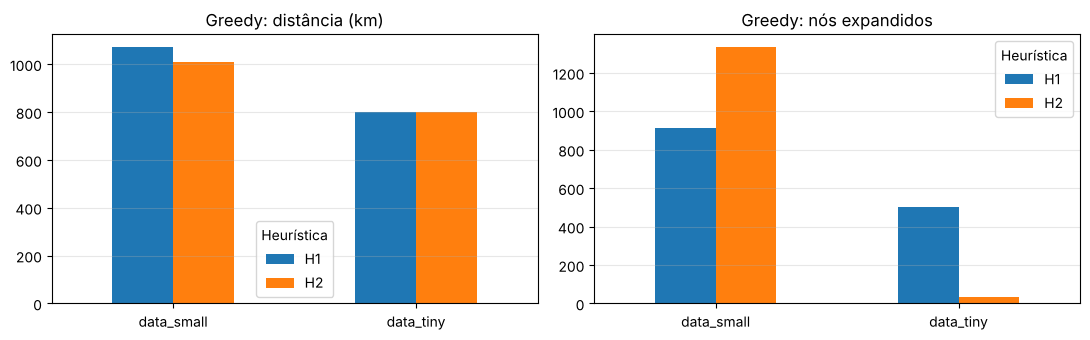

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
for eixo, coluna in zip(eixos, ["Distância (km)", "Nós expandidos"]):
    tabela = resultados_greedy.pivot(index="Dataset", columns="Heurística", values=coluna)
    tabela.plot(kind="bar", ax=eixo, rot=0)
    eixo.set_title(f"Greedy: {coluna.lower()}")
    eixo.set_xlabel("")
    eixo.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Rotas dos 2 veículos do tiny (melhor heurística)

In [6]:
nome = "data_tiny"
melhor = min(heuristicas, key=lambda h: check_solution(problemas[nome], solucoes[(nome, h)])[1])
print(f"Greedy com {melhor}\n")
print_solution(problemas[nome], solucoes[(nome, melhor)])

Greedy com H1

Solução válida | total: 798.54 km

Veículo 1 (capacidade 150 kg)
  30/10 09:00  pickup   Campos Leite                 [12, 23, 27, 28, 30, 33, 36, 38, 39] +37.7 km
  30/10 09:41  pickup   Hortas Valente               [5, 13, 25, 31, 32, 34, 37, 40] +23.6 km
  30/10 10:32  unload   Centro de Recolha 1          [5, 12, 13, 23, 25, 27, 28, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40] +30.6 km
  30/10 10:47  load     Centro de Recolha 1          [32, 33, 34, 35, 36, 37, 38, 39, 40, 25, 26, 27, 28, 29] +0.0 km
  30/10 12:15  deliver  Casa 2                       [36, 37, 38, 39, 40]     +36.1 km
  30/10 13:36  deliver  Loja 1                       [32, 33, 34, 35]         +53.7 km
  30/10 14:11  load     Centro de Recolha 1          [5, 6]                   +18.8 km
  31/10 07:45  pickup   Horta Morais                 [3, 4, 8, 9, 14, 17]     +29.1 km
  31/10 08:33  unload   Centro de Recolha 1          [3, 4, 8, 9, 14, 17]     +29.1 km
  31/10 09:20  deliver  Loja 5              

## 6. Efeito da janela de 2 horas

Para justificar a janela de 2 horas, corre-se o Greedy **sem janela** (só a passagem completa, com o mesmo limite de 5000 expansões).

In [7]:
linhas = []
for nome, prob in problemas.items():
    for h_nome, h in heuristicas.items():
        inicio = time.perf_counter()
        solucao, nos = greedy_search(prob, prob.initial_state(), h, janela_horas=None)
        tempo = time.perf_counter() - inicio
        com_janela = resultados_greedy[(resultados_greedy["Dataset"] == nome)
                                       & (resultados_greedy["Heurística"] == h_nome)].iloc[0]
        linhas.append({"Dataset": nome, "Heurística": h_nome,
                       "Com janela (km)": com_janela["Distância (km)"],
                       "Com janela (nós)": com_janela["Nós expandidos"],
                       "Sem janela (km)": check_solution(prob, solucao)[1] if solucao else "sem solução",
                       "Sem janela (nós)": nos, "Sem janela (s)": round(tempo, 1)})
pd.DataFrame(linhas)

,Dataset,Heurística,Com janela (km),Com janela (nós),Sem janela (km),Sem janela (nós),Sem janela (s)
0,data_tiny,H1,798.54,502,864.03,2469,10.9
1,data_tiny,H2,802.24,34,sem solução,5000,19.4
2,data_small,H1,1070.60,914,sem solução,5000,33.6
3,data_small,H2,1009.19,1333,sem solução,5000,35.0


## 7. Análise do Greedy

**Encontra sempre uma solução válida, e depressa.** Nos dois datasets e com as duas heurísticas, o Greedy encontra rotas que cumprem todas as restrições, entre menos de 1 segundo e cerca de 20 segundos.

**H1 vs H2.**
- No **tiny**, as duas dão soluções parecidas (798,54 e 802,24 km), mas a H2 precisa de muito menos nós (34 contra 502). Contar os locais que faltam visitar orienta melhor a pesquisa do que contar operações.
- No **small**, a H2 dá a melhor solução (1009,19 contra 1070,60 km), mas expande mais nós (1333 contra 914). A H2 tem muitos estados com o mesmo valor (o número de locais só desce quando o último item de um produtor é recolhido ou a última encomenda de um cliente é entregue), e o Greedy explora vários antes de encontrar um que a faça descer.

**A janela de 2 horas é essencial.** Sem ela, o Greedy dá uma solução pior no tiny com a H1 (864,03 contra 798,54 km, com quase 5 vezes mais nós) e, nos outros casos, não encontra solução em 5000 expansões. Sem janela, o Greedy "salta" para tarefas muito à frente no tempo (por exemplo, recolhas do dia seguinte) e deixa por fazer tarefas urgentes, que depois já não cabem nas janelas.

**Limitações.** O Greedy não garante a melhor solução: o Hill-Climbing (notebook `local_search.ipynb`) melhora estas soluções em 11% a 21%. Os limites usados para ser rápido (as 3 encomendas mais urgentes, poucos grupos de recolha e a janela de 2 horas) deixam de fora algumas combinações; em contrapartida, sem eles a pesquisa fica muito mais lenta.

## 8. A\*

*(Por completar.)*